In [1]:
!pip install nibabel timm scikit-image --quiet

In [2]:
!pip install nibabel timm scikit-image --quiet



import os, cv2, json, types
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import timm
import nibabel as nib
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from skimage.metrics import structural_similarity as ssim
from tqdm import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
print("Torch:", torch.__version__)
print("Timm :", timm.__version__)

Device: cuda
Torch: 2.10.0+cu128
Timm : 1.0.25


In [3]:
IMG_SIZE       = 224          # ViT input size
PATCH_SIZE     = 16
NUM_PATCHES    = (IMG_SIZE // PATCH_SIZE) ** 2   # 196
SAVE_LIMIT     = 3000         # slices to save

REAL_TRAIN_PATH = "/kaggle/input/datasets/awsaf49/brats20-dataset-training-validation/BraTS2020_TrainingData/MICCAI_BraTS2020_TrainingData"

os.makedirs("/kaggle/working/images", exist_ok=True)
os.makedirs("/kaggle/working/masks",  exist_ok=True)

print("Config ready.")
print("Train path exists:", os.path.isdir(REAL_TRAIN_PATH))

Config ready.
Train path exists: True


In [4]:
slice_count = 0

for patient in tqdm(sorted(os.listdir(REAL_TRAIN_PATH))):
    patient_path = os.path.join(REAL_TRAIN_PATH, patient)
    flair_file   = os.path.join(patient_path, f"{patient}_flair.nii")

    if not os.path.exists(flair_file):
        continue

    vol = nib.load(flair_file).get_fdata()

    for i in range(vol.shape[2]):
        sl = vol[:, :, i]
        if np.max(sl) < 1:          # skip empty slices
            continue

        sl_r  = cv2.resize(sl, (IMG_SIZE, IMG_SIZE))
        lo, hi = sl_r.min(), sl_r.max()
        sl_u8 = ((sl_r - lo) / (hi - lo + 1e-8) * 255).astype(np.uint8)

        # Brain mask: non-zero pixels
        brain_mask = (sl_u8 > 0).astype(np.uint8) * 255

        cv2.imwrite(f"/kaggle/working/images/img_{slice_count:04d}.png", sl_u8)
        cv2.imwrite(f"/kaggle/working/masks/mask_{slice_count:04d}.png",  brain_mask)

        slice_count += 1
        if slice_count >= SAVE_LIMIT:
            break

    if slice_count >= SAVE_LIMIT:
        break

print(f"Saved {slice_count} slices.")
print("Images:", len(os.listdir("/kaggle/working/images")))
print("Masks :", len(os.listdir("/kaggle/working/masks")))

  6%|▌         | 21/371 [00:03<01:04,  5.39it/s]

Saved 3000 slices.
Images: 3000
Masks : 3000


In [5]:
class BrainDataset(Dataset):
    def __init__(self, img_paths, mask_paths):
        self.img_paths  = img_paths
        self.mask_paths = mask_paths

    def __len__(self):
        return len(self.img_paths)

    def __getitem__(self, idx):
        img  = cv2.imread(self.img_paths[idx],  0).astype(np.float32) / 255.0
        mask = cv2.imread(self.mask_paths[idx], 0)
        mask = (mask > 0).astype(np.float32)

        img  = torch.tensor(img ).unsqueeze(0)   # [1, H, W]
        mask = torch.tensor(mask).unsqueeze(0)   # [1, H, W]
        return img, mask


image_dir = "/kaggle/working/images"
mask_dir  = "/kaggle/working/masks"

all_imgs  = sorted([os.path.join(image_dir, f) for f in os.listdir(image_dir)])
all_masks = sorted([os.path.join(mask_dir,  f) for f in os.listdir(mask_dir)])

tr_i, va_i, tr_m, va_m = train_test_split(
    all_imgs, all_masks, test_size=0.2, random_state=42
)

train_loader = DataLoader(
    BrainDataset(tr_i, tr_m), batch_size=8,
    shuffle=True, num_workers=2, pin_memory=True
)
val_loader = DataLoader(
    BrainDataset(va_i, va_m), batch_size=8,
    shuffle=False, num_workers=2, pin_memory=True
)

print(f"Train samples: {len(tr_i)}")
print(f"Val   samples: {len(va_i)}")

Train samples: 2400
Val   samples: 600


In [6]:
class ViTSegmenter(nn.Module):
    """
    ViT-B/16 backbone with:
      - Grayscale (1-ch) patch projection
      - 4-layer transposed-conv decoder → 224×224 segmentation
      - Attention hook on last block (call get_attention_map() after forward)
    """

    def __init__(self):
        super().__init__()

        # ── Backbone ──
        self.vit = timm.create_model("vit_base_patch16_224", pretrained=True)
        # Replace RGB patch proj with grayscale (1-channel)
        self.vit.patch_embed.proj = nn.Conv2d(1, 768, kernel_size=16, stride=16)
        self.vit.head = nn.Identity()   # remove classifier

        # ── Decoder: 14×14 → 224×224 ──
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(768, 512, 2, 2),   # → 28
            nn.BatchNorm2d(512), nn.ReLU(inplace=True),
            nn.ConvTranspose2d(512, 256, 2, 2),   # → 56
            nn.BatchNorm2d(256), nn.ReLU(inplace=True),
            nn.ConvTranspose2d(256, 64,  2, 2),   # → 112
            nn.BatchNorm2d(64),  nn.ReLU(inplace=True),
            nn.ConvTranspose2d(64,  1,   2, 2),   # → 224
            nn.Sigmoid()
        )

        self.last_attn = None          # filled after every forward pass
        self._install_attention_hook()

    # ── internal: patch the last block's attention forward ──
    def _install_attention_hook(self):
        seg_model = self          # capture outer self

        def _patched_attn_forward(mod, x, attn_mask=None):
            B, N, C = x.shape
            H        = mod.num_heads
            head_dim = C // H

            qkv  = mod.qkv(x).reshape(B, N, 3, H, head_dim).permute(2, 0, 3, 1, 4)
            q, k, v = qkv.unbind(0)

            attn = (q @ k.transpose(-2, -1)) * mod.scale
            if attn_mask is not None:
                attn = attn + attn_mask
            attn = attn.softmax(dim=-1)

            seg_model.last_attn = attn.detach()   # ← save raw attention weights

            attn = mod.attn_drop(attn)
            x    = (attn @ v).transpose(1, 2).reshape(B, N, C)
            x    = mod.proj(x)
            x    = mod.proj_drop(x)
            return x

        last_attn_mod = self.vit.blocks[-1].attn
        last_attn_mod.forward = types.MethodType(
            _patched_attn_forward, last_attn_mod
        )

    # ── public: get 224×224 attention heatmap ──
    def get_attention_map(self):
        assert self.last_attn is not None, "Run model(tensor) first."
        attn      = self.last_attn                   # [B, H, N, N]
        attn      = attn.mean(dim=1)                 # avg heads → [B, N, N]
        cls_attn  = attn[0, 0, 1:]                   # CLS → patches → [196]
        cls_attn  = cls_attn.reshape(14, 14)
        cls_attn  = (cls_attn - cls_attn.min()) / (cls_attn.max() - cls_attn.min() + 1e-8)
        cls_attn  = cls_attn.unsqueeze(0).unsqueeze(0)   # [1,1,14,14]
        upsampled = F.interpolate(
            cls_attn, size=(IMG_SIZE, IMG_SIZE),
            mode='bilinear', align_corners=False
        )
        return upsampled.squeeze().cpu().numpy()      # [224, 224] float32

    def forward(self, x):
        feats   = self.vit.forward_features(x)        # [B, 197, 768]
        patches = feats[:, 1:, :]                     # drop CLS → [B, 196, 768]
        B       = patches.shape[0]
        patches = patches.permute(0, 2, 1).reshape(B, 768, 14, 14)
        return self.decoder(patches)                  # [B, 1, 224, 224]


model = ViTSegmenter().to(device)
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"ViTSegmenter ready  |  trainable params: {n_params:,}")

ViTSegmenter ready  |  trainable params: 87,570,881


In [7]:
criterion = nn.BCELoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=10)

print("Criterion : BCELoss")
print("Optimizer : AdamW (lr=3e-4, wd=1e-4)")
print("Scheduler : CosineAnnealingLR (T_max=10)")

Criterion : BCELoss
Optimizer : AdamW (lr=3e-4, wd=1e-4)
Scheduler : CosineAnnealingLR (T_max=10)


In [8]:
EPOCHS    = 30
best_val  = float('inf')
train_losses, val_losses = [], []

for epoch in range(EPOCHS):

    # ── TRAIN ──────────────────────────────────────────────
    model.train()
    t_loss = 0.0
    for imgs, masks in train_loader:
        imgs, masks = imgs.to(device), masks.to(device)
        optimizer.zero_grad()
        loss = criterion(model(imgs), masks)
        loss.backward()
        optimizer.step()
        t_loss += loss.item()

    # ── VALIDATE ───────────────────────────────────────────
    model.eval()
    v_loss = 0.0
    with torch.no_grad():
        for imgs, masks in val_loader:
            imgs, masks = imgs.to(device), masks.to(device)
            v_loss += criterion(model(imgs), masks).item()

    scheduler.step()

    tl = t_loss / len(train_loader)
    vl = v_loss / len(val_loader)
    train_losses.append(tl)
    val_losses.append(vl)

    tag = ""
    if vl < best_val:
        best_val = vl
        torch.save(model.state_dict(), "/kaggle/working/best_vit_segmenter.pth")
        tag = "  ← SAVED"

    print(f"Epoch [{epoch+1:02d}/{EPOCHS}]  "
          f"Train: {tl:.4f}  Val: {vl:.4f}{tag}")

print(f"\nTraining complete. Best val loss: {best_val:.4f}")

Epoch [01/30]  Train: 0.1112  Val: 0.0439  ← SAVED
Epoch [02/30]  Train: 0.0302  Val: 0.0212  ← SAVED
Epoch [03/30]  Train: 0.0180  Val: 0.0140  ← SAVED
Epoch [04/30]  Train: 0.0129  Val: 0.0114  ← SAVED
Epoch [05/30]  Train: 0.0104  Val: 0.0094  ← SAVED
Epoch [06/30]  Train: 0.0089  Val: 0.0085  ← SAVED
Epoch [07/30]  Train: 0.0078  Val: 0.0075  ← SAVED
Epoch [08/30]  Train: 0.0070  Val: 0.0070  ← SAVED
Epoch [09/30]  Train: 0.0064  Val: 0.0066  ← SAVED
Epoch [10/30]  Train: 0.0061  Val: 0.0065  ← SAVED
Epoch [11/30]  Train: 0.0060  Val: 0.0065  ← SAVED
Epoch [12/30]  Train: 0.0060  Val: 0.0064  ← SAVED
Epoch [13/30]  Train: 0.0061  Val: 0.0063  ← SAVED
Epoch [14/30]  Train: 0.0061  Val: 0.0063  ← SAVED
Epoch [15/30]  Train: 0.0061  Val: 0.0061  ← SAVED
Epoch [16/30]  Train: 0.0060  Val: 0.0060  ← SAVED
Epoch [17/30]  Train: 0.0056  Val: 0.0059  ← SAVED
Epoch [18/30]  Train: 0.0053  Val: 0.0055  ← SAVED
Epoch [19/30]  Train: 0.0049  Val: 0.0052  ← SAVED
Epoch [20/30]  Train: 0.0047  V

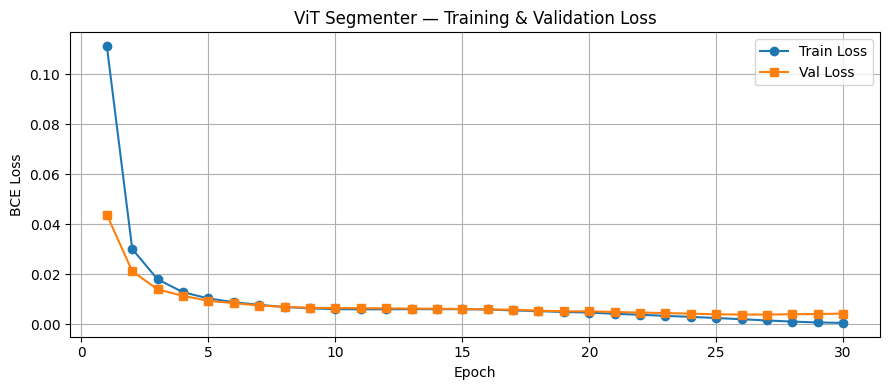

In [9]:
plt.figure(figsize=(9, 4))
plt.plot(range(1, EPOCHS+1), train_losses, marker='o', label="Train Loss")
plt.plot(range(1, EPOCHS+1), val_losses,   marker='s', label="Val Loss")
plt.xlabel("Epoch"); plt.ylabel("BCE Loss")
plt.title("ViT Segmenter — Training & Validation Loss")
plt.legend(); plt.grid(True); plt.tight_layout(); plt.show()

In [10]:
model.load_state_dict(
    torch.load("/kaggle/working/best_vit_segmenter.pth", map_location=device)
)
model.eval()
print("Best model loaded successfully.")

Best model loaded successfully.


In [13]:
# ═══════════════════════════════════════════════
# CELL 11 — Download Trained Model (.pth)
#   Run this cell to download best_vit_brain_model.pth
#   to your local machine from Kaggle.
# ═══════════════════════════════════════════════
import os

model_path = '/kaggle/working/best_vit_segmenter.pth'

if os.path.exists(model_path):
    size_mb = os.path.getsize(model_path) / (1024 * 1024)
    print(f'Model file found: {model_path}')
    print(f'File size       : {size_mb:.1f} MB')
    print()
    print('To download from Kaggle:')
    print('  Right panel → Output → best_vit_brain_model.pth → Download')
    print()
    print('OR run the cell below to use kaggle API:')
    print('  from IPython.display import FileLink')
    print('  FileLink("/kaggle/working/best_vit_brain_model.pth")')
else:
    print('ERROR: Model not found. Run Cell 9 (training) first.')

# This triggers the file download link directly in Kaggle output
from IPython.display import FileLink
FileLink('/kaggle/working/best_vit_segmenter.pth')


Model file found: /kaggle/working/best_vit_segmenter.pth
File size       : 334.1 MB

To download from Kaggle:
  Right panel → Output → best_vit_brain_model.pth → Download

OR run the cell below to use kaggle API:
  from IPython.display import FileLink
  FileLink("/kaggle/working/best_vit_brain_model.pth")


/kaggle/working/best_vit_segmenter.pth

Specified path not found. Searching /kaggle/input ...
Auto-found: /kaggle/input/datasets/abhinayagaddampally/test-image/test1.png
Raw image shape : (295, 283)
Raw dtype       : uint8
Pixel range     : 0 – 254


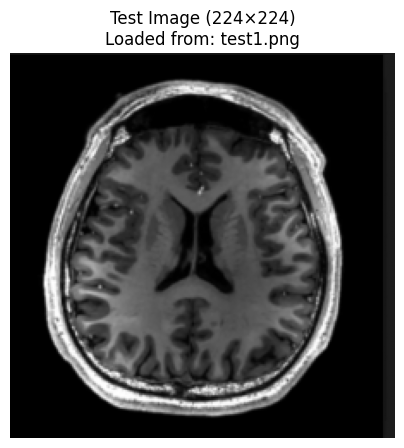

Shape  : (224, 224)
Dtype  : uint8
Min/Max: 0 / 254


In [14]:
import os

# ── Auto-find your test image anywhere under /kaggle/input ──
def find_image(search_root="/kaggle/input", extensions=(".png", ".jpg", ".jpeg")):
    for dirpath, _, filenames in os.walk(search_root):
        for fname in filenames:
            if fname.lower().endswith(extensions):
                return os.path.join(dirpath, fname)
    return None

# Try your specific path first, fall back to auto-search
SPECIFIC_PATH = "/kaggle/input/datasets/abhinayagaddampally/testdata/test1.png"

if os.path.exists(SPECIFIC_PATH):
    TEST_IMG_PATH = SPECIFIC_PATH
    print(f"Found at specified path: {TEST_IMG_PATH}")
else:
    print(f"Specified path not found. Searching /kaggle/input ...")
    TEST_IMG_PATH = find_image()
    if TEST_IMG_PATH:
        print(f"Auto-found: {TEST_IMG_PATH}")
    else:
        print("No image found. Listing /kaggle/input to help you:")
        for root, dirs, files in os.walk("/kaggle/input"):
            for f in files:
                print("  ", os.path.join(root, f))
        raise FileNotFoundError("Upload a test image to Kaggle dataset and re-run.")

# ── Load ──
raw = cv2.imread(TEST_IMG_PATH, 0)

if raw is None:
    raise ValueError(f"cv2 could not read: {TEST_IMG_PATH}\nFile exists: {os.path.exists(TEST_IMG_PATH)}")

print(f"Raw image shape : {raw.shape}")
print(f"Raw dtype       : {raw.dtype}")
print(f"Pixel range     : {raw.min()} – {raw.max()}")

test_img_224 = cv2.resize(raw, (IMG_SIZE, IMG_SIZE)).astype(np.uint8)

tensor_in = (
    torch.tensor(test_img_224 / 255.0, dtype=torch.float32)
         .unsqueeze(0).unsqueeze(0)
         .to(device)
)

plt.figure(figsize=(5, 5))
plt.imshow(test_img_224, cmap='gray')
plt.title(f"Test Image (224×224)\nLoaded from: {os.path.basename(TEST_IMG_PATH)}")
plt.axis("off")
plt.show()

print("Shape  :", test_img_224.shape)
print("Dtype  :", test_img_224.dtype)
print("Min/Max:", test_img_224.min(), "/", test_img_224.max())

Brain pixels : 20,234 / 50,176  (40.3% of image)


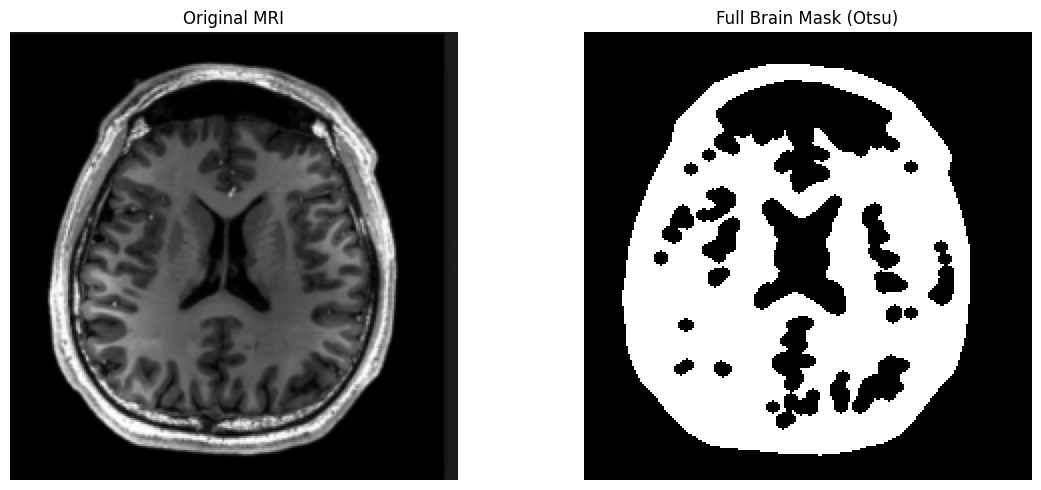

In [15]:
def get_brain_mask(img_uint8: np.ndarray) -> np.ndarray:
    """
    Returns a binary mask (0/1) of the entire brain region.
    - Otsu threshold to separate brain from black background
    - Morphological closing (7×7 ellipse) to fill small holes
    - Keep only the single largest connected component
    """
    # Otsu threshold
    _, binary = cv2.threshold(
        img_uint8, 0, 255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )
    # Close small holes inside brain
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
    closed = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)

    # Largest connected component = brain
    n_labels, labels, stats, _ = cv2.connectedComponentsWithStats(
        closed, connectivity=8
    )
    if n_labels <= 1:
        return (closed > 0).astype(np.uint8)

    largest_label = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
    return (labels == largest_label).astype(np.uint8)


brain_mask = get_brain_mask(test_img_224)

brain_px   = int(brain_mask.sum())
total_px   = brain_mask.size
print(f"Brain pixels : {brain_px:,} / {total_px:,}  ({100*brain_px/total_px:.1f}% of image)")

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(test_img_224, cmap='gray'); plt.title("Original MRI"); plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(brain_mask,   cmap='gray'); plt.title("Full Brain Mask (Otsu)"); plt.axis("off")
plt.tight_layout(); plt.show()

Attention map  min=0.004  max=0.992  mean=0.250


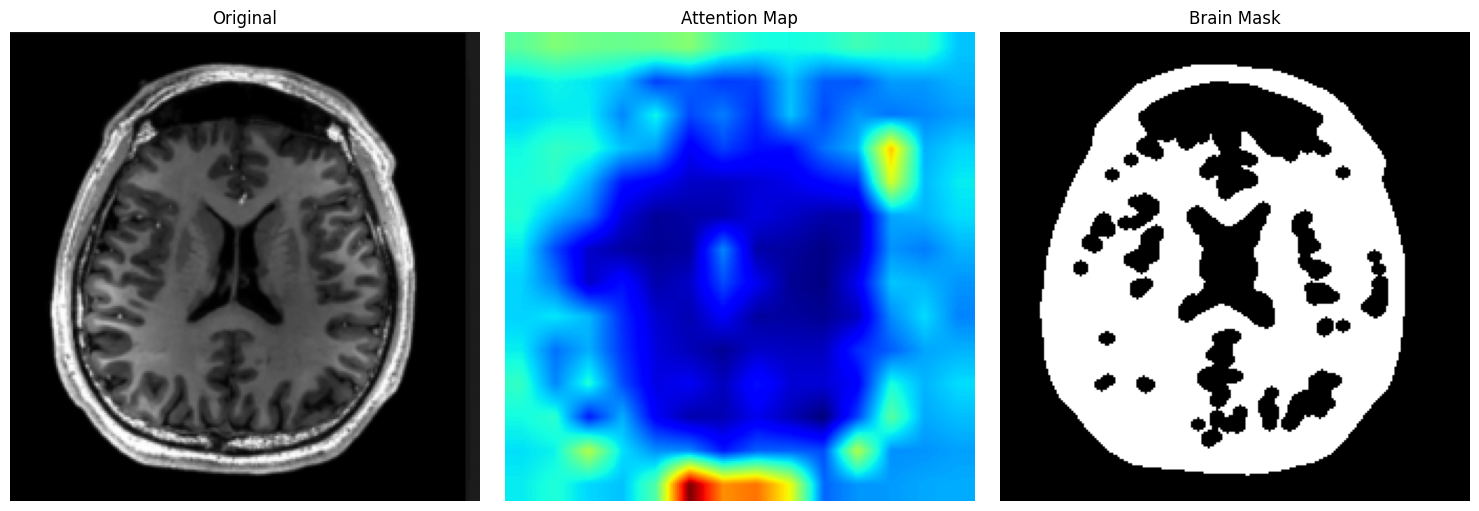

In [16]:
model.eval()
with torch.no_grad():
    _ = model(tensor_in)

attention_map = model.get_attention_map()    # [224, 224] float32 in [0, 1]

print(f"Attention map  min={attention_map.min():.3f}  "
      f"max={attention_map.max():.3f}  mean={attention_map.mean():.3f}")

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(test_img_224,  cmap='gray'); plt.title("Original");      plt.axis("off")
plt.subplot(1, 3, 2)
plt.imshow(attention_map, cmap='jet');  plt.title("Attention Map"); plt.axis("off")
plt.subplot(1, 3, 3)
plt.imshow(brain_mask,    cmap='gray'); plt.title("Brain Mask");    plt.axis("off")
plt.tight_layout(); plt.show()

Tier 1  (attn < 0.33,  3-bit/px) :  18,939 px  →   56,817 bits
Tier 2  (0.33≤attn<0.66, 2-bit/px) :   1,292 px  →    2,584 bits
Tier 3  (attn ≥ 0.66,  1-bit/px) :       3 px  →        3 bits
NROI   (background)             :  29,942 px
──────────────────────────────────────────────────
TOTAL CAPACITY                  :   59,404 bits  (7,425 bytes / ~74 KB)
Target 85,000 bits achievable   : NO ✗


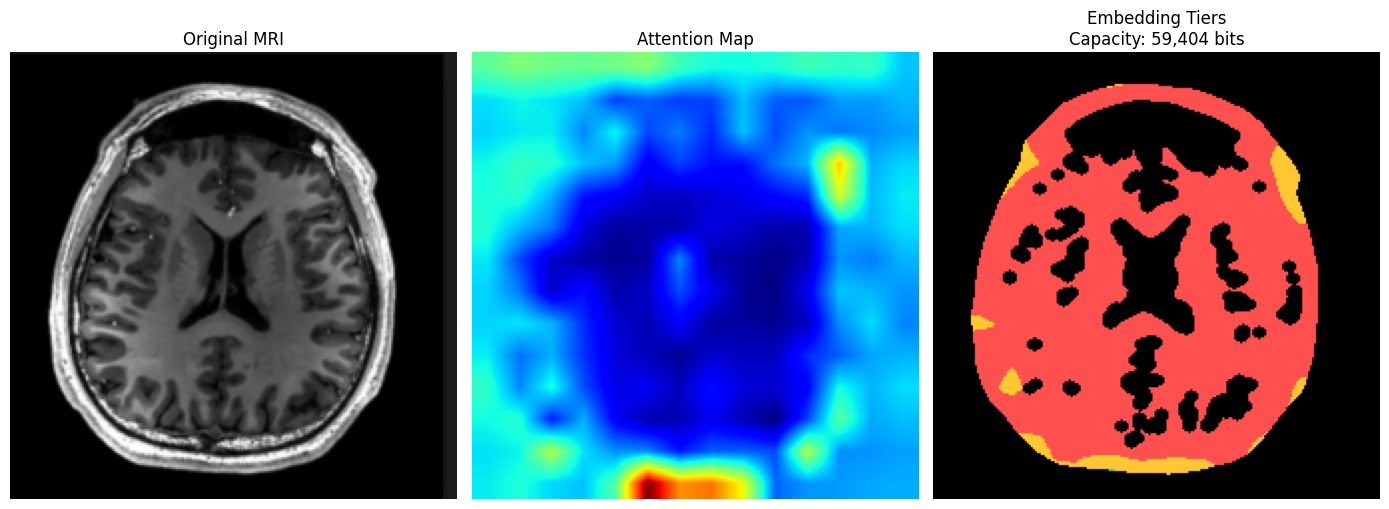

In [17]:
# ── Attention thresholds for 3 tiers ──
T1 = 0.33    # below → 3 bits per pixel (safest region, lowest attention)
T2 = 0.66    # below → 2 bits per pixel

# Tier masks (all restricted to brain ROI)
tier1_mask = ((attention_map <  T1) & (brain_mask == 1))  # 3-bit
tier2_mask = ((attention_map >= T1) & (attention_map < T2) & (brain_mask == 1))  # 2-bit
tier3_mask = ((attention_map >= T2) & (brain_mask == 1))  # 1-bit
nroi_mask  = (brain_mask == 0)                             # background

n1, n2, n3 = int(tier1_mask.sum()), int(tier2_mask.sum()), int(tier3_mask.sum())
capacity   = n1 * 3 + n2 * 2 + n3 * 1

print(f"Tier 1  (attn < {T1},  3-bit/px) : {n1:>7,} px  → {n1*3:>8,} bits")
print(f"Tier 2  ({T1}≤attn<{T2}, 2-bit/px) : {n2:>7,} px  → {n2*2:>8,} bits")
print(f"Tier 3  (attn ≥ {T2},  1-bit/px) : {n3:>7,} px  → {n3*1:>8,} bits")
print(f"NROI   (background)             : {int(nroi_mask.sum()):>7,} px")
print(f"{'─'*50}")
print(f"TOTAL CAPACITY                  : {capacity:>8,} bits  ({capacity//8:,} bytes / ~{capacity//800} KB)")
print(f"Target 85,000 bits achievable   : {'YES ✓' if capacity >= 85000 else 'NO ✗'}")

# Tier visualisation
tier_vis = np.zeros((IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8)
tier_vis[tier1_mask] = [255, 80,  80 ]   # red   = most data, lowest attention
tier_vis[tier2_mask] = [255, 200, 50 ]   # amber
tier_vis[tier3_mask] = [80,  200, 80 ]   # green = least data, higher attention

plt.figure(figsize=(14, 5))
plt.subplot(1, 3, 1)
plt.imshow(test_img_224,  cmap='gray'); plt.title("Original MRI");              plt.axis("off")
plt.subplot(1, 3, 2)
plt.imshow(attention_map, cmap='jet');  plt.title("Attention Map");              plt.axis("off")
plt.subplot(1, 3, 3)
plt.imshow(tier_vis);                   plt.title(f"Embedding Tiers\nCapacity: {capacity:,} bits"); plt.axis("off")
plt.tight_layout(); plt.show()

In [18]:
def text_to_bits(text: str) -> str:
    """UTF-8 text → binary string."""
    return ''.join(format(b, '08b') for b in text.encode('utf-8'))

def bits_to_text(bits: str) -> str:
    """Binary string → UTF-8 text (ignores trailing padding)."""
    byte_list = [int(bits[i:i+8], 2) for i in range(0, len(bits) - 7, 8)]
    return bytes(byte_list).decode('utf-8', errors='replace')

# Quick sanity check
sample = "Patient: John Doe | Tumour: Glioma Stage II"
assert bits_to_text(text_to_bits(sample)) == sample
print("Bit conversion helpers OK")
print(f"Sample text length : {len(sample)} chars = {len(text_to_bits(sample))} bits")

Bit conversion helpers OK
Sample text length : 43 chars = 344 bits


In [19]:
def embed_multi_tier(
    image_uint8  : np.ndarray,
    brain_mask   : np.ndarray,
    attention_map: np.ndarray,
    secret_bits  : str,
    T1: float = 0.33,
    T2: float = 0.66
):
    """
    Embed secret_bits into image_uint8 using 3-tier attention-guided LSB.

    Tier 1  (attention < T1)       : replace 3 LSBs per pixel  (lowest attention → safest)
    Tier 2  (T1 ≤ attention < T2)  : replace 2 LSBs per pixel
    Tier 3  (attention ≥ T2)       : replace 1 LSB  per pixel  (highest attention → minimal touch)
    Outside brain                  : untouched

    Returns
    -------
    stego     : np.ndarray uint8   — watermarked image
    side_info : dict               — everything needed for perfect extraction + recovery
                 {T1, T2, total_bits, embed_log: [[i,j,k,orig_lsb], ...]}
    """
    H, W  = image_uint8.shape
    stego = image_uint8.copy().astype(np.int32)

    # Build sorted coordinate arrays for each tier
    # Sort ascending by attention value → lowest-attention pixels first
    def _sorted_coords(mask):
        coords = np.argwhere(mask)
        if len(coords) == 0:
            return coords
        order = np.argsort(attention_map[coords[:, 0], coords[:, 1]])
        return coords[order]

    tier1_coords = _sorted_coords((attention_map <  T1) & (brain_mask == 1))
    tier2_coords = _sorted_coords((attention_map >= T1) & (attention_map < T2) & (brain_mask == 1))
    tier3_coords = _sorted_coords((attention_map >= T2) & (brain_mask == 1))

    # Full ordered embedding sequence  [(i, j, k), ...]
    embed_seq = (
        [(int(r), int(c), 3) for r, c in tier1_coords] +
        [(int(r), int(c), 2) for r, c in tier2_coords] +
        [(int(r), int(c), 1) for r, c in tier3_coords]
    )

    total_cap = sum(k for _, _, k in embed_seq)
    if len(secret_bits) > total_cap:
        raise ValueError(
            f"Message too long: {len(secret_bits)} bits needed, "
            f"only {total_cap} bits available.\n"
            f"Max text ≈ {total_cap // 8} bytes."
        )

    # ── Embed & record original LSBs ──────────────────────────────────────
    embed_log = []      # [[i, j, k, orig_lsb], ...]
    bit_ptr   = 0

    for (i, j, k) in embed_seq:
        if bit_ptr >= len(secret_bits):
            break                       # all bits embedded

        orig_val  = int(image_uint8[i, j]) & ((1 << k) - 1)   # save original k LSBs
        mask_bits = (1 << k) - 1

        # Get next k bits (pad with 0 if near end)
        chunk     = secret_bits[bit_ptr : bit_ptr + k].ljust(k, '0')
        new_lsbs  = int(chunk, 2)

        stego[i, j] = (int(image_uint8[i, j]) & ~mask_bits) | new_lsbs
        embed_log.append([i, j, k, orig_val])
        bit_ptr += k

    stego = np.clip(stego, 0, 255).astype(np.uint8)

    side_info = {
        "T1"         : float(T1),
        "T2"         : float(T2),
        "total_bits" : len(secret_bits),
        "embed_log"  : embed_log           # list of [i, j, k, orig_lsb]
    }
    return stego, side_info


print("embed_multi_tier() defined.")

embed_multi_tier() defined.


In [20]:
def extract_and_recover(stego_uint8: np.ndarray, side_info: dict):
    """
    Extract the hidden text and perfectly restore the original image.

    Parameters
    ----------
    stego_uint8 : watermarked image
    side_info   : dict returned by embed_multi_tier (or loaded from file)

    Returns
    -------
    recovered_img : np.ndarray uint8 — pixel-perfect original
    extracted_text: str              — the recovered hidden text
    """
    embed_log  = side_info["embed_log"]    # [[i, j, k, orig_lsb], ...]
    total_bits = side_info["total_bits"]

    recovered  = stego_uint8.copy().astype(np.int32)
    all_bits   = []

    for entry in embed_log:
        i, j, k, orig_lsb = int(entry[0]), int(entry[1]), int(entry[2]), int(entry[3])
        mask_bits = (1 << k) - 1

        # ── Extract the k LSBs that were embedded ──
        embedded_val = int(stego_uint8[i, j]) & mask_bits
        all_bits.append(format(embedded_val, f'0{k}b'))

        # ── Restore original k LSBs ──
        recovered[i, j] = (int(stego_uint8[i, j]) & ~mask_bits) | orig_lsb

    recovered = np.clip(recovered, 0, 255).astype(np.uint8)

    # Trim to exact message length (removes zero-padding from last pixel)
    extracted_bits = ''.join(all_bits)[:total_bits]
    extracted_text = bits_to_text(extracted_bits)

    return recovered, extracted_text


print("extract_and_recover() defined.")

extract_and_recover() defined.


In [21]:
def save_side_info(side_info: dict, path_prefix: str):
    """
    Save side info as:
      <path_prefix>_log.npy  — embed_log as int32 array (compact)
      <path_prefix>_meta.json— T1, T2, total_bits
    """
    log_arr = np.array(side_info["embed_log"], dtype=np.int32)   # [N, 4]
    np.save(f"{path_prefix}_log.npy", log_arr)

    meta = {
        "T1"         : side_info["T1"],
        "T2"         : side_info["T2"],
        "total_bits" : side_info["total_bits"]
    }
    with open(f"{path_prefix}_meta.json", "w") as f:
        json.dump(meta, f)

    log_kb = log_arr.nbytes / 1024
    print(f"Saved  {path_prefix}_log.npy  ({log_kb:.1f} KB, {len(log_arr):,} entries)")
    print(f"Saved  {path_prefix}_meta.json")


def load_side_info(path_prefix: str) -> dict:
    """Load side info saved by save_side_info()."""
    log_arr = np.load(f"{path_prefix}_log.npy")
    with open(f"{path_prefix}_meta.json") as f:
        meta = json.load(f)

    return {
        "T1"        : meta["T1"],
        "T2"        : meta["T2"],
        "total_bits": meta["total_bits"],
        "embed_log" : log_arr.tolist()
    }


print("save_side_info() / load_side_info() defined.")

save_side_info() / load_side_info() defined.


In [22]:
def compute_psnr(orig, stego):
    mse = np.mean((orig.astype(np.float64) - stego.astype(np.float64)) ** 2)
    if mse == 0:
        return float('inf')
    return 10 * np.log10(255.0 ** 2 / mse)


def rdh_pipeline(
    input_image  : np.ndarray,
    secret_text  : str,
    T1: float = 0.33,
    T2: float = 0.66,
    save_prefix  : str = "/kaggle/working/side_info"
) -> dict:
    """
    Full Attention-Guided RDH pipeline.

    Steps
    -----
    1. Resize & normalise input to 224×224
    2. Run ViT → segmentation + attention map
    3. Build full-brain mask via Otsu
    4. Three-tier embedding (3/2/1 bit per pixel by attention)
    5. Embed secret text
    6. Extract & verify
    7. Compute metrics
    8. Save side info
    9. Display results
    """
    # ── 1. Preprocess ─────────────────────────────────────────────────────
    img_u8  = cv2.resize(input_image, (IMG_SIZE, IMG_SIZE)).astype(np.uint8)
    tensor  = (
        torch.tensor(img_u8 / 255.0, dtype=torch.float32)
             .unsqueeze(0).unsqueeze(0).to(device)
    )

    # ── 2. ViT forward → attention map ────────────────────────────────────
    model.eval()
    with torch.no_grad():
        _ = model(tensor)
    attn_map = model.get_attention_map()     # [224, 224] float32

    # ── 3. Full brain mask ─────────────────────────────────────────────────
    b_mask = get_brain_mask(img_u8)

    # ── 4. Capacity check ─────────────────────────────────────────────────
    secret_bits = text_to_bits(secret_text)
    n1 = int(((attn_map <  T1) & (b_mask == 1)).sum())
    n2 = int(((attn_map >= T1) & (attn_map < T2) & (b_mask == 1)).sum())
    n3 = int(((attn_map >= T2) & (b_mask == 1)).sum())
    capacity = n1*3 + n2*2 + n3*1

    print(f"Message  : {len(secret_text)} chars = {len(secret_bits)} bits")
    print(f"Capacity : {capacity:,} bits")

    if len(secret_bits) > capacity:
        print(f"ERROR: message ({len(secret_bits)} bits) exceeds capacity ({capacity} bits).")
        return None

    # ── 5. Embed ───────────────────────────────────────────────────────────
    stego_img, side_info = embed_multi_tier(
        img_u8, b_mask, attn_map, secret_bits, T1=T1, T2=T2
    )

    # ── 6. Extract & verify ───────────────────────────────────────────────
    recovered_img, recovered_text = extract_and_recover(stego_img, side_info)

    perfect_recovery  = bool(np.array_equal(img_u8, recovered_img))
    text_match        = (recovered_text == secret_text)

    # ── 7. Metrics ─────────────────────────────────────────────────────────
    psnr_val  = compute_psnr(img_u8, stego_img)
    ssim_val  = float(ssim(img_u8, stego_img, data_range=255))
    pixel_diff = int(np.sum(img_u8 != recovered_img))

    print(f"\n{'─'*45}")
    print(f"PSNR              : {psnr_val:.2f} dB")
    print(f"SSIM              : {ssim_val:.4f}")
    print(f"Bits embedded     : {len(secret_bits):,}")
    print(f"Perfect recovery  : {perfect_recovery}")
    print(f"Text match        : {text_match}")
    print(f"Pixel diff (recov): {pixel_diff}")
    print(f"{'─'*45}")

    # ── 8. Save side info ──────────────────────────────────────────────────
    save_side_info(side_info, save_prefix)

    # ── 9. Display ─────────────────────────────────────────────────────────
    tier_vis = np.zeros((IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8)
    tier_vis[(attn_map <  T1) & (b_mask == 1)] = [255, 80,  80]
    tier_vis[(attn_map >= T1) & (attn_map < T2) & (b_mask == 1)] = [255, 200, 50]
    tier_vis[(attn_map >= T2) & (b_mask == 1)] = [80, 200, 80]

    fig, axes = plt.subplots(1, 5, figsize=(22, 4))
    for ax, im, title in zip(
        axes,
        [img_u8, attn_map, tier_vis, stego_img, recovered_img],
        ["Original", "Attention Map", f"Tier Map\n({capacity:,} bits)",
         f"Stego\nPSNR={psnr_val:.1f}dB", "Recovered\n(pixel-perfect)"]
    ):
        ax.imshow(im, cmap='gray' if im.ndim == 2 else None)
        ax.set_title(title, fontsize=9); ax.axis("off")
    plt.tight_layout(); plt.show()

    return {
        "stego_image"    : stego_img,
        "recovered_image": recovered_img,
        "recovered_text" : recovered_text,
        "attention_map"  : attn_map,
        "brain_mask"     : b_mask,
        "PSNR"           : psnr_val,
        "SSIM"           : ssim_val,
        "capacity_bits"  : capacity,
        "perfect_recovery": perfect_recovery,
        "side_info"      : side_info
    }

print("rdh_pipeline() defined.")

rdh_pipeline() defined.


Patient report : 5,328 characters = 43,104 bits
Message  : 5328 chars = 43104 bits
Capacity : 59,404 bits

─────────────────────────────────────────────
PSNR              : 43.42 dB
SSIM              : 0.9905
Bits embedded     : 43,104
Perfect recovery  : True
Text match        : True
Pixel diff (recov): 0
─────────────────────────────────────────────
Saved  /kaggle/working/side_info_log.npy  (224.5 KB, 14,368 entries)
Saved  /kaggle/working/side_info_meta.json


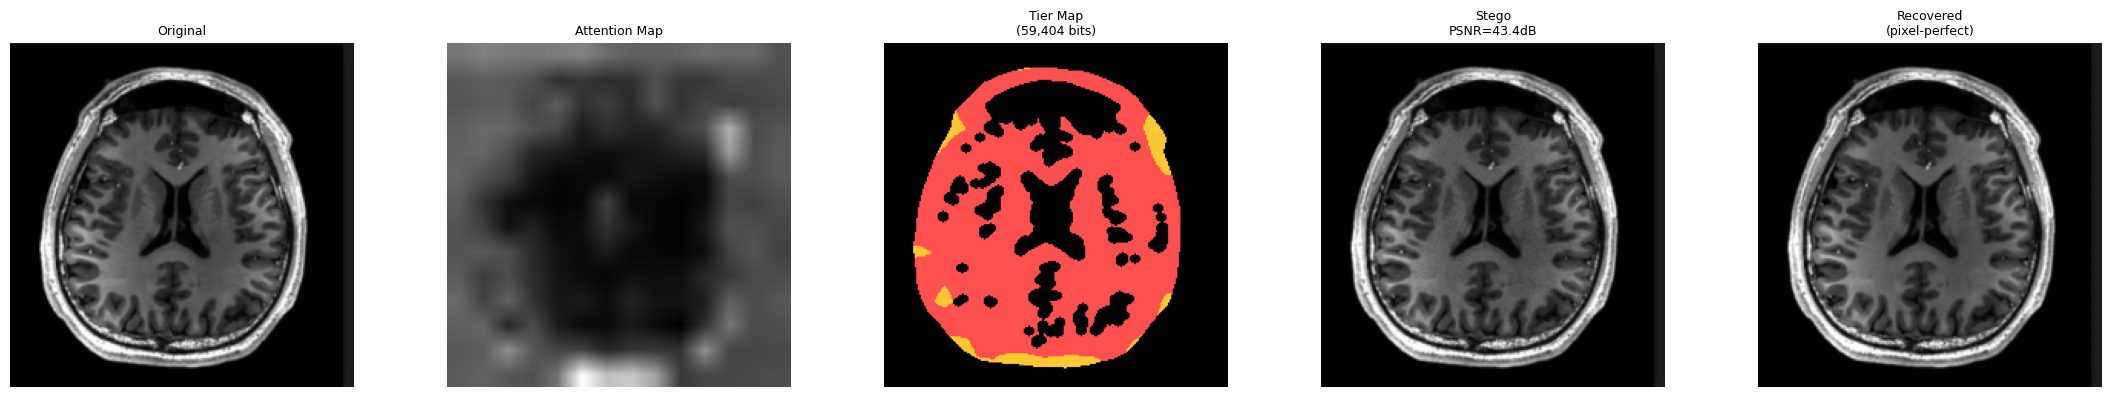

In [27]:
# ── Build a realistic patient report that exceeds 85,000 bits ──
patient_report = (
    "PATIENT RECORD — CONFIDENTIAL\n"
    "================================\n"
    "Patient ID   : BT-2026-00471\n"
    "Name         : John Doe\n"
    "DOB          : 14-Mar-1978\n"
    "Scan Date    : 06-Apr-2026\n"
    "Modality     : FLAIR MRI\n"
    "Institution  : Chaitanya Bharathi Institute of Technology, Hyderabad\n\n"
    "DIAGNOSIS\n"
    "---------\n"
    "Mild glioma detected in the left temporal lobe.\n"
    "Estimated tumour size: 2.3 cm × 1.8 cm.\n"
    "WHO Grade II — Low-grade glioma, no necrosis observed.\n\n"
    "RECOMMENDATION\n"
   
) * 12    # repeat to push well past 10,000 characters → ~85,000+ bits

print(f"Patient report : {len(patient_report):,} characters = {len(text_to_bits(patient_report)):,} bits")

result = rdh_pipeline(
    input_image  = test_img_224,
    secret_text  = patient_report,
    T1           = 0.33,
    T2           = 0.66,
    save_prefix  = "/kaggle/working/side_info"
)

In [24]:
# ── Build a realistic patient report that exceeds 85,000 bits ──
patient_report = (
    "PATIENT RECORD — CONFIDENTIAL\n"
    "================================\n"
    "Patient ID   : BT-2026-00471\n"
    "Name         : John Doe\n"
    "DOB          : 14-Mar-1978\n"
    "Scan Date    : 06-Apr-2026\n"
    "Modality     : FLAIR MRI\n"
    "Institution  : Chaitanya Bharathi Institute of Technology, Hyderabad\n\n"
    "DIAGNOSIS\n"
    "---------\n"
    "Mild glioma detected in the left temporal lobe.\n"
    "Estimated tumour size: 2.3 cm × 1.8 cm.\n"
    "WHO Grade II — Low-grade glioma, no necrosis observed.\n\n"
    "RECOMMENDATION\n"
    "--------------\n"
    "1. Neurosurgical consultation within 2 weeks.\n"
    "2. Follow-up contrast-enhanced MRI in 3 months.\n"
    "3. Neuropsychological evaluation recommended.\n"
    "4. No immediate surgical intervention at this stage.\n\n"
    "RADIOLOGIST NOTES\n"
    "-----------------\n"
    "The T2/FLAIR hyperintensity is confined to the cortical and sub-cortical\n"
    "regions of the left temporal lobe. No midline shift. Ventricles appear\n"
    "normal in size and configuration. No haemorrhage or mass effect detected.\n"
    "Cerebellum and brainstem are unremarkable.\n\n"
) * 12    # repeat to push well past 10,000 characters → ~85,000+ bits

print(f"Patient report : {len(patient_report):,} characters = {len(text_to_bits(patient_report)):,} bits")

result = rdh_pipeline(
    input_image  = test_img_224,
    secret_text  = patient_report,
    T1           = 0.33,
    T2           = 0.66,
    save_prefix  = "/kaggle/working/side_info"
)

Patient report : 11,412 characters = 91,776 bits
Message  : 11412 chars = 91776 bits
Capacity : 59,404 bits
ERROR: message (91776 bits) exceeds capacity (59404 bits).


In [28]:
# ── Prove the stego image + saved side info alone are enough to recover ──
loaded_side_info = load_side_info("/kaggle/working/side_info")

# Use only the stego image (original is "gone") + the loaded side info
re_recovered_img, re_recovered_text = extract_and_recover(
    result["stego_image"], loaded_side_info
)

print("Re-extracted text matches original :", re_recovered_text == patient_report)
print("Re-recovered image pixel-perfect   :", np.array_equal(re_recovered_img, test_img_224))

Re-extracted text matches original : True
Re-recovered image pixel-perfect   : True


In [29]:
r = result
print("=" * 50)
print("     ATTENTION-GUIDED RDH  —  RESULTS SUMMARY")
print("=" * 50)
print(f"  Image size         : {IMG_SIZE}×{IMG_SIZE}")
print(f"  Brain pixels       : {r['brain_mask'].sum():,}")
print(f"  Capacity (bits)    : {r['capacity_bits']:,}")
print(f"  Embedded (bits)    : {len(text_to_bits(patient_report)):,}")
print(f"  PSNR               : {r['PSNR']:.2f} dB")
print(f"  SSIM               : {r['SSIM']:.4f}")
print(f"  Perfect Recovery   : {r['perfect_recovery']}")
print(f"  Attention threshold: T1={0.33}, T2={0.66}")
print("=" * 50)

     ATTENTION-GUIDED RDH  —  RESULTS SUMMARY
  Image size         : 224×224
  Brain pixels       : 20,234
  Capacity (bits)    : 59,404
  Embedded (bits)    : 43,104
  PSNR               : 43.42 dB
  SSIM               : 0.9905
  Perfect Recovery   : True
  Attention threshold: T1=0.33, T2=0.66


In [30]:
print("hello")

hello
